# Comprehensive Mobile Price Analysis

This notebook uses the labeled [course training dataset](https://github.com/devtlv/MiniProject-DataAnalysis-W6D5-Mobile_Price_Classification/blob/main/train.csv). Extract the project, keep `train.csv` beside the notebook, install `numpy pandas scipy matplotlib` in your Jupyter environment, and run all cells. The target is an ordered price category from 0 (lowest) to 3 (highest).

# 1. Load and explore the training data

Pandas loads the dataset and summarizes its structure. Inspect both data types and meaning: a numeric storage type may represent a continuous measurement, a count, or a binary category.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Load the exact course CSV and separate the target from the predictor names.
raw = pd.read_csv("train.csv")
target = "price_range"
features = raw.columns.drop(target).tolist()
binary = ["blue", "dual_sim", "four_g", "three_g", "touch_screen", "wifi"]

# Record types, distinct values, and missing counts before preprocessing.
audit = pd.DataFrame({
    "dtype": raw.dtypes,
    "distinct": raw.nunique(),
    "missing": raw.isna().sum(),
})
audit["role"] = "Numeric predictor"
audit.loc[binary, "role"] = "Binary predictor"
audit.loc[target, "role"] = "Ordinal target"
print(f"Rows: {len(raw):,} | Predictors: {len(features)}")
print(audit.to_string())
print("\nRaw descriptive overview:")
print(raw.describe().T.round(3).to_string())


Rows: 2,000 | Predictors: 20
                 dtype  distinct  missing               role
battery_power    int64      1094        0  Numeric predictor
blue             int64         2        0   Binary predictor
clock_speed    float64        26        0  Numeric predictor
dual_sim         int64         2        0   Binary predictor
fc               int64        20        0  Numeric predictor
four_g           int64         2        0   Binary predictor
int_memory       int64        63        0  Numeric predictor
m_dep          float64        10        0  Numeric predictor
mobile_wt        int64       121        0  Numeric predictor
n_cores          int64         8        0  Numeric predictor
pc               int64        21        0  Numeric predictor
px_height        int64      1137        0  Numeric predictor
px_width         int64      1109        0  Numeric predictor
ram              int64      1562        0  Numeric predictor
sc_h             int64        15        0  Numeric predi

# 2. Clean and preprocess

The source already encodes yes/no features as 0/1, so verify and retain that encoding. Keep price tier as an ordinal integer. Treat zero pixel height and zero physical screen width as unavailable measurements. Other zeros can carry meaning, such as no front camera megapixels. Use available values for each analysis to avoid inventing screen measurements.

In [2]:
# Remove exact duplicates, then verify the categorical codes.
phones = raw.drop_duplicates().copy()
assert phones[binary].isin([0, 1]).all().all(), "Unexpected binary code."
assert phones[target].isin([0, 1, 2, 3]).all(), "Unexpected price tier."
phones[binary] = phones[binary].astype("int8")
phones[target] = phones[target].astype("int8")

# Replace impossible zero dimensions with missing values in those fields only.
dimension_columns = ["px_height", "sc_w"]
invalid_dimensions = phones[dimension_columns].le(0)
phones[dimension_columns] = phones[dimension_columns].mask(invalid_dimensions)
print(f"Exact duplicates removed: {len(raw) - len(phones):,}")
print("Dimensions flagged as unavailable:\n", invalid_dimensions.sum().to_string())
print("\nPrice-tier counts:\n", phones[target].value_counts().sort_index().to_string())


Exact duplicates removed: 0
Dimensions flagged as unavailable:
 px_height      2
sc_w         180

Price-tier counts:
 price_range
0    500
1    500
2    500
3    500


# 3A. Measure each feature's distribution

The variance and standard deviation are sample estimates (ddof=1). Skewness measures asymmetry. Excess kurtosis uses a normal-distribution reference of zero. A mode can be tied, so the table reports the smallest mode and the number of tied modes.

In [3]:
# Drop missing observations feature by feature, then pass arrays to NumPy/SciPy.
records = []
for feature in features:
    values = phones[feature].dropna().to_numpy()
    unique_values, frequencies = np.unique(values, return_counts=True)
    tied_modes = unique_values[frequencies == frequencies.max()]
    records.append({
        "feature": feature,
        "n": values.size,
        "mean": np.mean(values),
        "median": np.median(values),
        "mode": stats.mode(values, keepdims=False).mode,
        "mode_ties": tied_modes.size,
        "range": np.ptp(values),
        "variance": np.var(values, ddof=1),
        "std": np.std(values, ddof=1),
        "skew": stats.skew(values, bias=False),
        "excess_kurtosis": stats.kurtosis(values, fisher=True, bias=False),
    })

feature_stats = pd.DataFrame(records).set_index("feature")
print(feature_stats.round(3).to_string())


                  n      mean  median    mode  mode_ties   range     variance       std   skew  excess_kurtosis
feature                                                                                                        
battery_power  2000  1238.518  1226.0   618.0          3  1497.0   193088.360   439.418  0.032           -1.224
blue           2000     0.495     0.0     0.0          1     1.0        0.250     0.500  0.020           -2.002
clock_speed    2000     1.522     1.5     0.5          1     2.5        0.666     0.816  0.178           -1.323
dual_sim       2000     0.509     1.0     1.0          1     1.0        0.250     0.500 -0.038           -2.001
fc             2000     4.310     3.0     0.0          1    19.0       18.848     4.341  1.020            0.277
four_g         2000     0.522     1.0     1.0          1     1.0        0.250     0.500 -0.086           -1.995
int_memory     2000    32.046    32.0    27.0          1    62.0      329.267    18.146  0.058          

# 3B. Test RAM across price tiers

The Kruskal–Wallis test checks the null hypothesis that RAM distributions are the same across the four tiers. Its rank-based statistic can detect differences in location or shape. The six two-sided Mann–Whitney follow-ups use Holm correction to control the family-wise error rate. Rank-biserial effects are positive when the higher-price tier tends to have more RAM.

In [4]:
# Build the four independent groups and run a tie-corrected omnibus rank test.
ram_groups = [phones.loc[phones[target].eq(tier), "ram"].dropna().to_numpy()
              for tier in range(4)]
omnibus = stats.kruskal(*ram_groups)
print("Median RAM by tier (MB):", [np.median(group).item() for group in ram_groups])
omnibus_p = f"= {omnibus.pvalue:.3g}" if omnibus.pvalue else "< 1e-300"
print(f"Kruskal-Wallis H(3) = {omnibus.statistic:.2f}; p {omnibus_p}")

# Adjust p-values in ascending order, then restore the original order.
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted_sorted = np.maximum.accumulate(p_values[order] * np.arange(len(order), 0, -1))
    adjusted = np.empty_like(p_values)
    adjusted[order] = np.minimum(adjusted_sorted, 1)
    return adjusted

# Compare every pair and calculate an effect size from the U statistic.
pairs = []
for lower, higher in itertools.combinations(range(4), 2):
    high_ram, low_ram = ram_groups[higher], ram_groups[lower]
    result = stats.mannwhitneyu(high_ram, low_ram, alternative="two-sided", method="asymptotic")
    effect = 2 * result.statistic / (high_ram.size * low_ram.size) - 1
    pairs.append((lower, higher, result.statistic, result.pvalue, effect))
posthoc = pd.DataFrame(pairs, columns=["Lower tier", "Higher tier", "U", "p",
                                       "Rank-biserial effect"])
posthoc["Holm p"] = holm_adjust(posthoc["p"])
print(posthoc.to_string(index=False, float_format=lambda value: f"{value:.5g}"))


Median RAM by tier (MB): [719.5, 1686.5, 2577.0, 3509.5]
Kruskal-Wallis H(3) = 1681.50; p < 1e-300
 Lower tier  Higher tier          U           p  Rank-biserial effect      Holm p
          0            1 2.3209e+05  1.312e-121               0.85672  3.936e-121
          0            2 2.4936e+05 2.7738e-163               0.99484 1.1095e-162
          0            3    2.5e+05 5.8536e-165                     1 3.5121e-164
          1            2 2.2688e+05 2.9706e-110               0.81505 2.9706e-110
          1            3 2.4948e+05 1.3463e-163               0.99581 6.7316e-163
          2            3 2.2731e+05 3.6216e-111               0.81848 7.2431e-111


# 3C. Rank feature associations with price tier

Spearman’s rho uses ranks and can detect monotonic relationships with an ordered target. Use complete pairs for each feature and correct across the 20 comparisons with Holm's method. A displayed p-value of 0 means numerical underflow. An association describes this dataset and may reflect other specifications measured on the same phones.

In [5]:
# Calculate each feature's rank correlation with the target and correct its p-value.
results = []
for feature in features:
    pair = phones[[feature, target]].dropna()
    rho, p_value = stats.spearmanr(pair[feature], pair[target])
    results.append((feature, len(pair), rho, p_value))
ranking = pd.DataFrame(results, columns=["Feature", "n", "Spearman rho", "p"])
ranking["Holm p"] = holm_adjust(ranking["p"])
ranking = ranking.sort_values("Spearman rho", key=np.abs, ascending=False)
print(ranking.to_string(index=False, float_format=lambda value: f"{value:.5g}"))
print("\nSignificant after Holm correction at 5%:",
      ", ".join(ranking.loc[ranking["Holm p"] < 0.05, "Feature"]))


      Feature    n  Spearman rho          p     Holm p
          ram 2000       0.91708          0          0
battery_power 2000       0.19999 1.7223e-19 3.2724e-18
     px_width 2000       0.16513 1.0741e-13 1.9333e-12
    px_height 1998       0.13292  2.456e-09 4.1753e-08
   int_memory 2000      0.044278   0.047717    0.76346
           pc 2000      0.032824    0.14227          1
 touch_screen 2000     -0.030411    0.17399          1
    mobile_wt 2000     -0.030214     0.1768          1
           fc 2000      0.024167    0.28003          1
         sc_h 2000      0.023727    0.28888          1
      three_g 2000      0.023611    0.29124          1
    talk_time 2000      0.022138    0.32241          1
         blue 2000      0.020573     0.3578          1
         wifi 2000      0.018785    0.40112          1
     dual_sim 2000      0.017444    0.43556          1
       four_g 2000      0.014772     0.5091          1
         sc_w 1820      0.014054    0.54906          1
  clock_sp

# 4. Visualize distributions and relationships

The histogram shows the distribution of RAM across all phones. The scatter plot compares RAM with battery capacity and colors points by tier. The box plot shows the middle 50% of RAM within each tier and marks the median. The heatmap uses a diverging scale centered at zero.

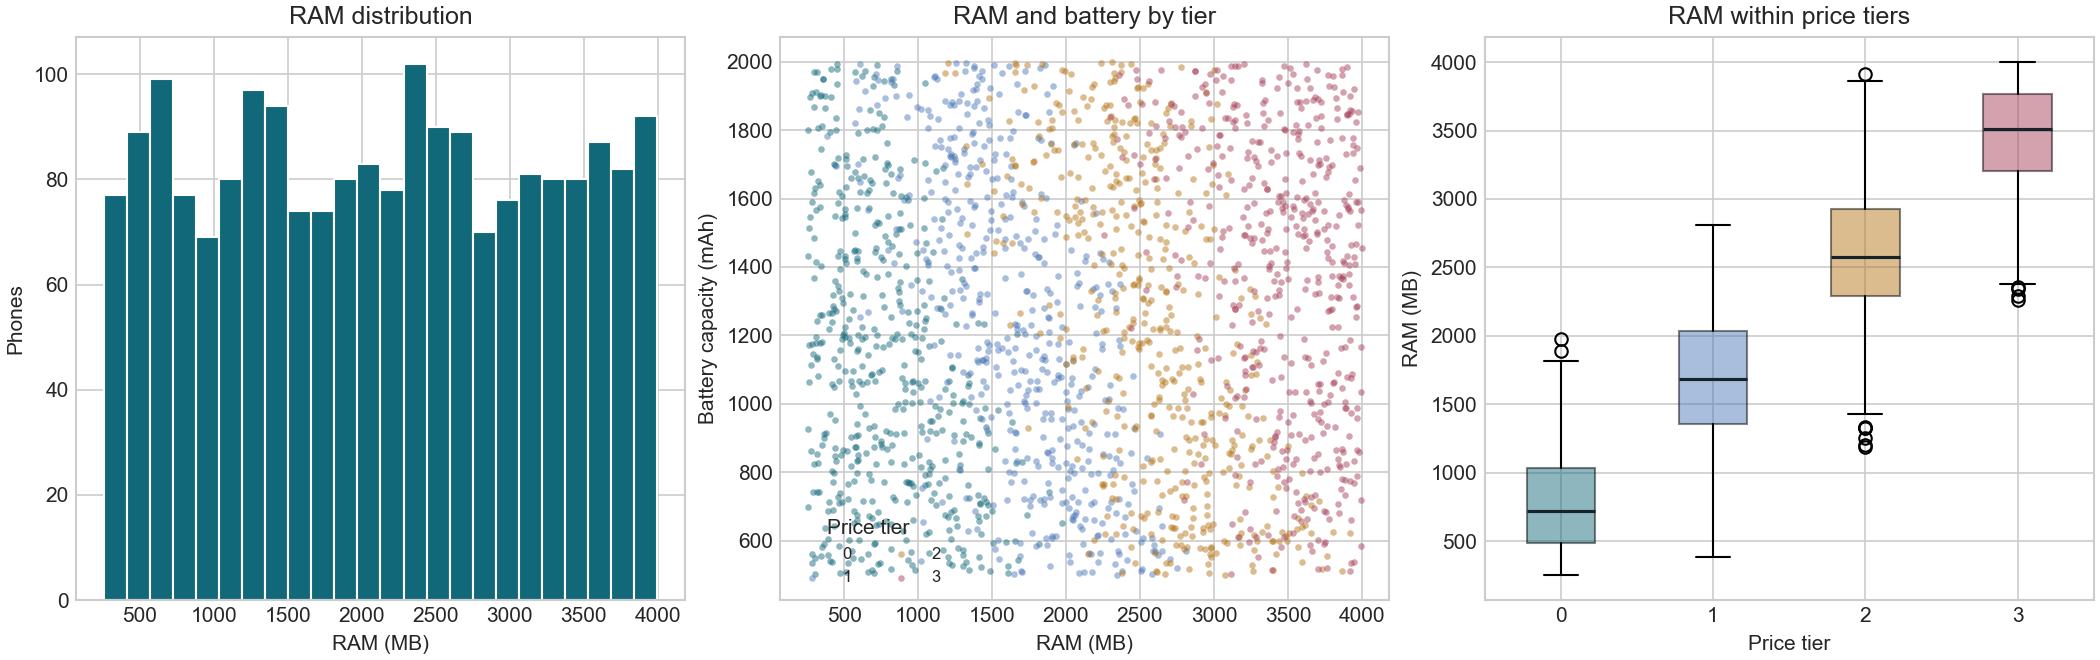

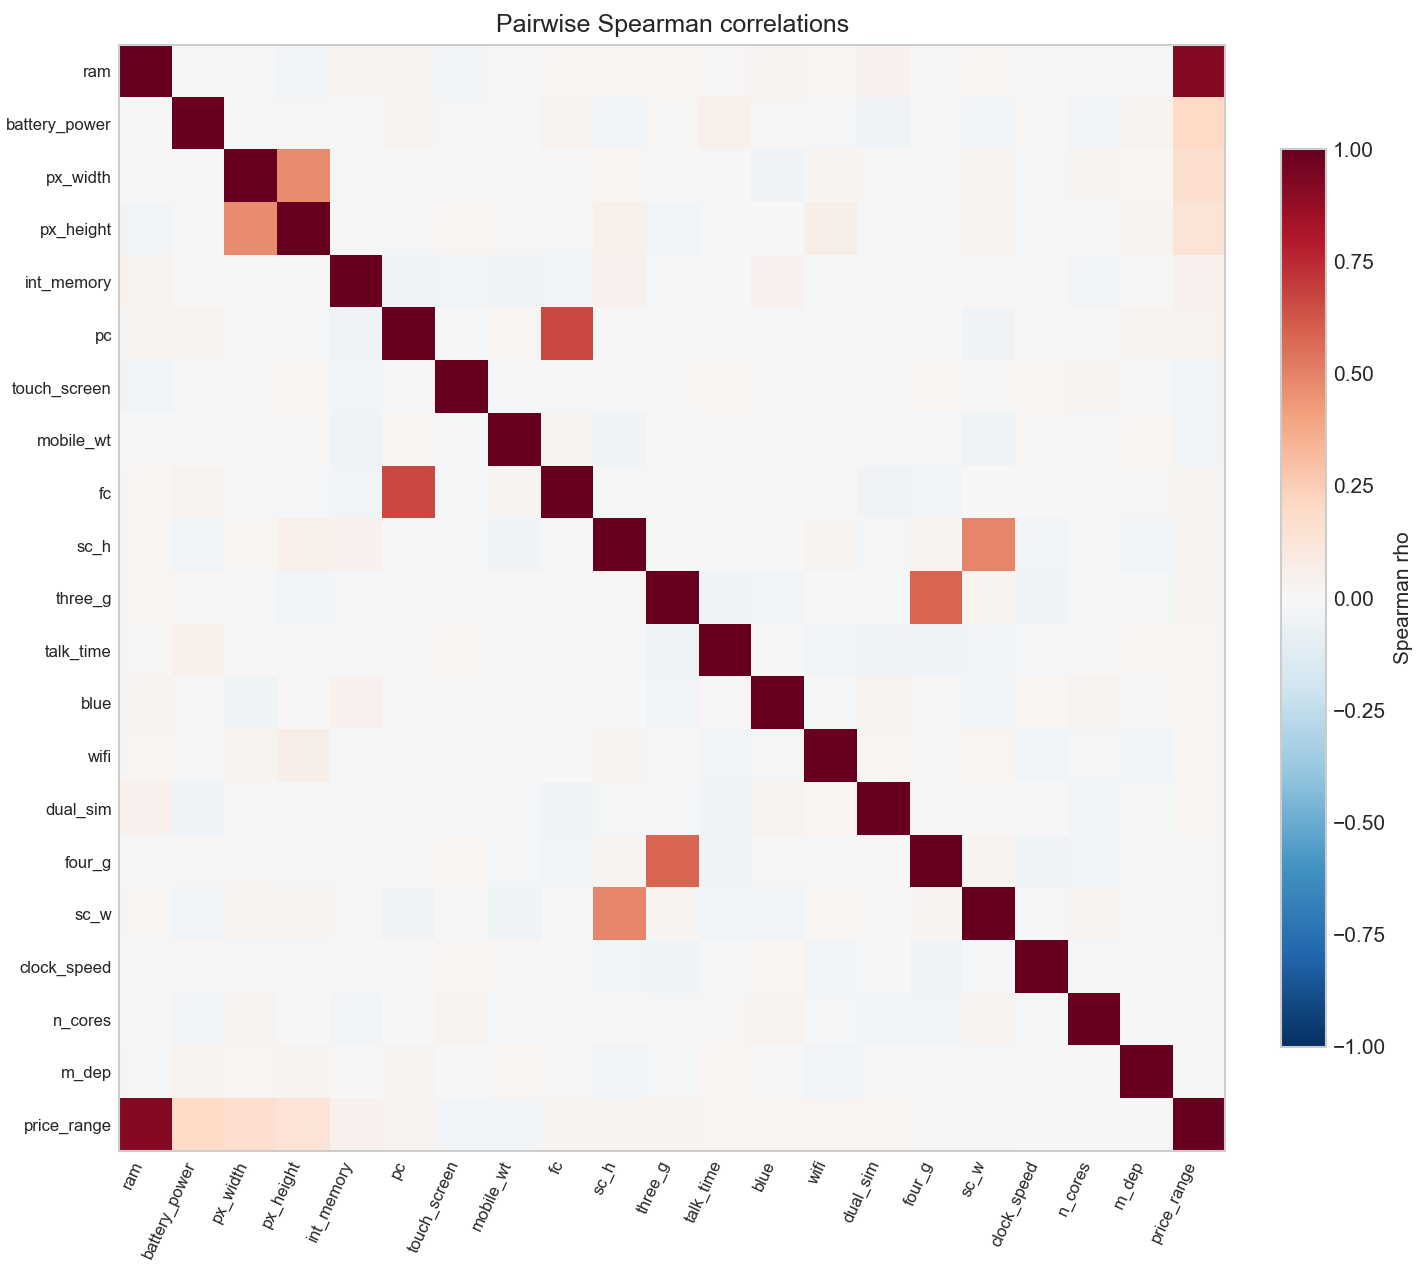

In [6]:
plt.style.use("seaborn-v0_8-whitegrid")
colors = ["#116879", "#4a77b7", "#b57316", "#a63e57"]

# Use complementary plots to inspect the strongest association.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), layout="constrained")
axes[0].hist(phones["ram"], bins=24, color=colors[0], edgecolor="white")
axes[0].set(title="RAM distribution", xlabel="RAM (MB)", ylabel="Phones")
for tier, color in enumerate(colors):
    group = phones.loc[phones[target].eq(tier)]
    axes[1].scatter(group["ram"], group["battery_power"], s=10, alpha=0.48,
                    color=color, label=str(tier), linewidths=0)
axes[1].set(title="RAM and battery by tier", xlabel="RAM (MB)", ylabel="Battery capacity (mAh)")
axes[1].legend(title="Price tier", ncol=2, fontsize=8)
boxes = axes[2].boxplot(ram_groups, tick_labels=["0", "1", "2", "3"], patch_artist=True,
                       medianprops={"color": "#16232b", "linewidth": 1.5})
for box, color in zip(boxes["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.48)
axes[2].set(title="RAM within price tiers", xlabel="Price tier", ylabel="RAM (MB)")
fig.savefig("feature_distributions.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

# Show the full pairwise Spearman matrix. Put price_range last for easy scanning.
ordered_features = ranking["Feature"].tolist() + [target]
correlations = phones[ordered_features].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9.5, 8.5), layout="constrained")
heat = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
ticks = np.arange(len(correlations))
ax.set_xticks(ticks, correlations.columns, rotation=65, ha="right", fontsize=8)
ax.set_yticks(ticks, correlations.index, fontsize=8)
ax.grid(False)
ax.set_title("Pairwise Spearman correlations")
fig.colorbar(heat, ax=ax, shrink=0.78, label="Spearman rho")
fig.savefig("spearman_heatmap.png", dpi=150)
if plt.get_backend().lower() != "agg":
    plt.show()
plt.close(fig)

# 5. Synthesize the findings

RAM is the strongest individual feature in this training dataset. Its box plots show a clear upward shift across price tiers, although some tiers overlap. Battery capacity and display resolution have smaller positive associations. Internal memory appears associated at the unadjusted 5% threshold, but its association becomes statistically inconclusive after correction across the 20 features. The binary feature encodings make comparisons convenient, but a small or statistically inconclusive rank correlation alone leaves open whether a feature could contribute in a multivariable model. A separate held-out evaluation would be needed to measure predictive performance.

In [7]:
# Print a compact answer table and summarize the statistical decision.
top_features = ranking.head(5)[["Feature", "Spearman rho", "Holm p"]]
print("Largest absolute feature-to-tier correlations:")
print(top_features.to_string(index=False, float_format=lambda value: f"{value:.5g}"))
significant_pairs = posthoc["Holm p"].lt(0.05).sum()
print(f"RAM: {significant_pairs} of {len(posthoc)} tier pairs differ after Holm correction.")
print("These are associations within the labeled training data. Price tier has no currency units.")



Largest absolute feature-to-tier correlations:
      Feature  Spearman rho     Holm p
          ram       0.91708          0
battery_power       0.19999 3.2724e-18
     px_width       0.16513 1.9333e-12
    px_height       0.13292 4.1753e-08
   int_memory      0.044278    0.76346
RAM: 6 of 6 tier pairs differ after Holm correction.
These are associations within the labeled training data. Price tier has no currency units.
